# How the Steinmetz et al. 2019 spreadsheet is measured

1. **The task and stimuli.** What the mouse sees and does on each trial, and what else happens in a session.
2. **What is in the release?** Which mice, which files, what we kept.
3. **From that, how do we get the spreadsheet numbers?** Subjects, trials, neurons, length, sizes.
4. **Figures.** Probes in the brain, neurons and trials per session, trial conditions, regions, raster.

The data lives on HAL (`~/ismael/steinmetz2019/data/sessions`): the 39 session folders of figshare 9598406.
`data/steinmetz2019/steinmetz_extract.py` reduced them there to the small tables in `data/steinmetz2019/tables/`, which
this notebook reads.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

here = Path.cwd().resolve()
REPO = here
for candidate in [here, *here.parents]:
    if (candidate / "src" / "ladys").is_dir() or (candidate / "data" / "steinmetz2019" / "tables").exists():
        REPO = candidate
        break
TABLES = REPO / "data" / "steinmetz2019" / "tables"
FIGURE_DIR = REPO / "tutorials" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert TABLES.exists(), f"Expected extracted tables at {TABLES}; see data/steinmetz2019/README.md"
GB = 1e9

sessions = pd.read_parquet(TABLES / "sessions.parquet")
probes = pd.read_parquet(TABLES / "probes.parquet")
units = pd.read_parquet(TABLES / "units.parquet")
trials = pd.read_parquet(TABLES / "trials.parquet")
channels = pd.read_parquet(TABLES / "channels.parquet")
epochs = pd.read_parquet(TABLES / "epochs.parquet")
files = pd.read_parquet(TABLES / "files.parquet")
release = pd.read_csv(TABLES / "release_files.csv")
good = units[units.good]
CONTRASTS = [0, 0.25, 0.5, 1]
trials["condition"] = [f"L{l * 100:.0f} R{r * 100:.0f}" for l, r in zip(trials.contrast_left, trials.contrast_right)]
trials["correct_response"] = np.select(
    [trials.contrast_left > trials.contrast_right, trials.contrast_right > trials.contrast_left, trials.contrast_left == 0],
    ["left choice", "right choice", "NoGo"], "either (50 %)")
trials["choice_name"] = trials.choice.map({1: "left choice", -1: "right choice", 0: "NoGo"})

## 1. The task and stimuli

Paper Fig. 1a–d (Steinmetz et al. 2019; figshare `fig1_BehavAndRec.jpg`, CC BY 4.0):

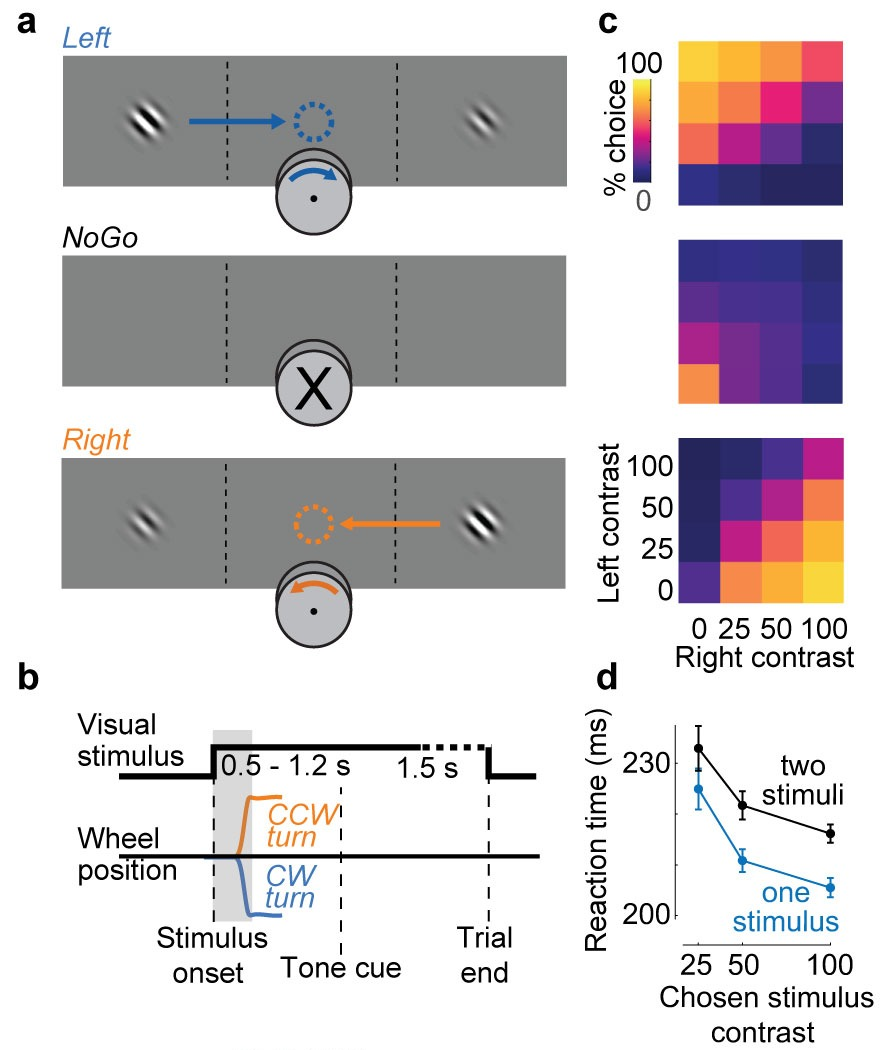

In [2]:
display(Image(filename=str(FIGURE_DIR / "steinmetz_paper_task.jpg"), width=620))

**One trial** (paper Fig. 1a, b; Methods):

1. The mouse holds the wheel still for 0.2–0.5 s; then the trial starts.
2. **Stimulus:** a grating (Gabor, 45°, σ = 9°) appears on the left screen, the right screen, both or neither, each at
   contrast 0, 25, 50 or 100 %.
3. After a random 0.5–1.2 s the **go cue** sounds (8 kHz tone, 0.2 s). The mouse may move earlier, but the stimulus
   is locked in place and no reward is available until the go cue.
4. **Response:** turning the wheel moves the stimuli. Bringing the higher-contrast grating to the centre screen is
   correct (left grating → turn so it moves right, *left choice*; right grating → *right choice*). With no grating,
   holding still for 1.5 s (*NoGo*) is correct. With two equal non-zero gratings, left or right is rewarded at random.
5. **Feedback:** water (2–3 µL) if correct, a 1 s white-noise sound if wrong. 1 s later the next trial can start.

So a **condition** is one (left contrast, right contrast) pair: 4 × 4 = **16 conditions**, and three responses (left,
right, NoGo) can be correct. After a mistake on an "easy" condition (blank, or 100 % against 0 or 25 %) the
condition is repeated (`repNum` counts the repeats; 1,749 trials).

**A session** (~45–68 min) is more than the task. After the task come receptive-field mapping with sparse noise
(white squares at random positions, ~0.12 Hz), then **passive replay** (the task's gratings, go-cue beeps, valve clicks
and white noise, without reward), with spontaneous periods (grey screen) in between. Spikes are released for the whole
session.

Below, from the release: the 16 conditions with their correct response and trial counts, how often the mice chose each
response (compare paper Fig. 1c, which uses the 9,538 `included` trials), and when the go cue, response and feedback
come after the stimulus.

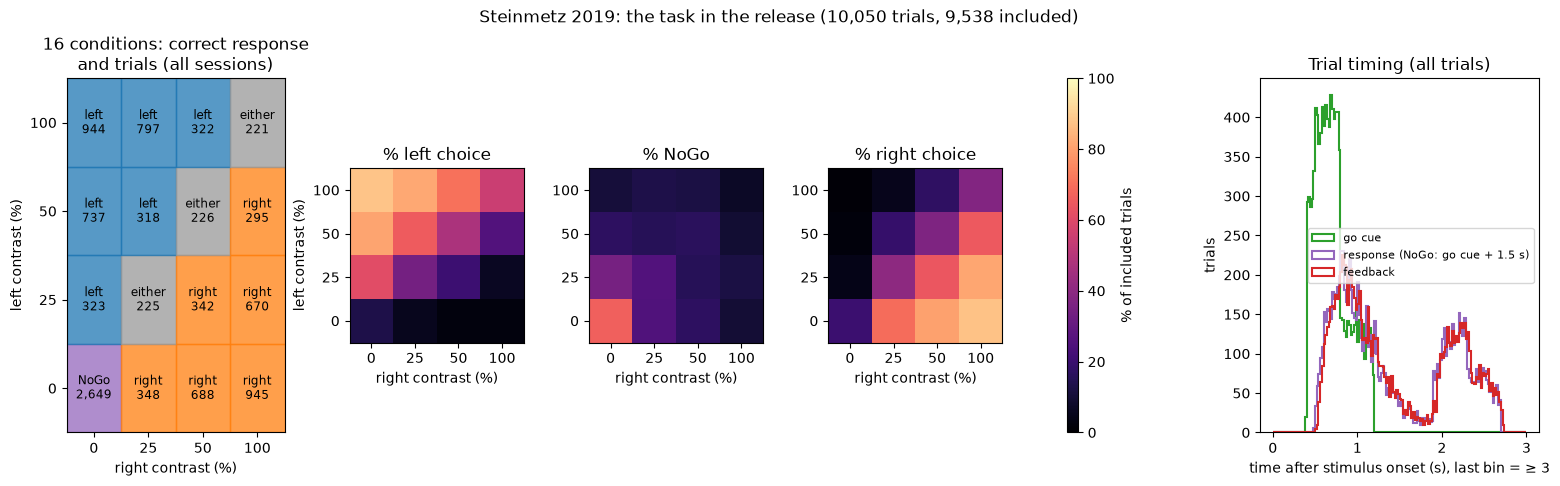

,min,5%,50%,95%,max
seconds after stimulus,,,,,
go cue,0.395,0.432,0.676,1.112,1.199
response,0.479,0.618,1.183,2.513,2.714
feedback,0.495,0.650,1.205,2.532,2.738


In [3]:
RESP_COLOR = {"left choice": "#1f77b4", "right choice": "#ff7f0e", "NoGo": "#9467bd", "either (50 %)": "0.6"}
fig = plt.figure(figsize=(19, 4.6))
gs = fig.add_gridspec(1, 7, width_ratios=[1.25, 1, 1, 1, 0.06, 0.3, 1.6], wspace=0.42)
ax = fig.add_subplot(gs[0])
n = trials.groupby(["contrast_left", "contrast_right"]).size()
for i, cl in enumerate(CONTRASTS):
    for j, cr in enumerate(CONTRASTS):
        resp = trials[(trials.contrast_left == cl) & (trials.contrast_right == cr)].correct_response.iloc[0]
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=RESP_COLOR[resp], alpha=0.75))
        ax.text(j + 0.5, i + 0.5, f"{resp.split(' ')[0]}\n{n[(cl, cr)]:,}", ha="center", va="center", fontsize=8.5)
ax.set(xlim=(0, 4), ylim=(0, 4), xticks=np.arange(4) + 0.5, yticks=np.arange(4) + 0.5, xticklabels=[0, 25, 50, 100],
       yticklabels=[0, 25, 50, 100], xlabel="right contrast (%)", ylabel="left contrast (%)",
       title="16 conditions: correct response\nand trials (all sessions)")
inc = trials[trials.included]
for k, name in enumerate(["left choice", "NoGo", "right choice"]):
    ax = fig.add_subplot(gs[k + 1])
    p = inc.assign(c=inc.choice_name == name).pivot_table("c", "contrast_left", "contrast_right") * 100
    im = ax.imshow(p.to_numpy(), origin="lower", cmap="magma", vmin=0, vmax=100)
    ax.set(xticks=range(4), yticks=range(4), xticklabels=[0, 25, 50, 100], yticklabels=[0, 25, 50, 100],
           xlabel="right contrast (%)", title=f"% {name}")
    if k == 0:
        ax.set_ylabel("left contrast (%)")
plt.colorbar(im, cax=fig.add_subplot(gs[4]), label="% of included trials")
ax = fig.add_subplot(gs[6])
bins = np.arange(0, 3.01, 0.02)
for col, label, color in [("go_cue_time", "go cue", "C2"), ("response_time", "response (NoGo: go cue + 1.5 s)", "C4"),
                          ("feedback_time", "feedback", "C3")]:
    ax.hist((trials[col] - trials.stim_time).clip(upper=3), bins=bins, histtype="step", lw=1.5, color=color, label=label)
ax.set(xlabel="time after stimulus onset (s), last bin = ≥ 3", ylabel="trials", title="Trial timing (all trials)")
ax.legend(fontsize=8)
fig.suptitle(f"Steinmetz 2019: the task in the release ({len(trials):,} trials, {len(inc):,} included)", y=1.03)
fig.savefig(FIGURE_DIR / "steinmetz_task.png", dpi=150, bbox_inches="tight")
plt.show()
lat = pd.DataFrame({k: (trials[c] - trials.stim_time) for k, c in [("go cue", "go_cue_time"), ("response", "response_time"),
                                                                  ("feedback", "feedback_time")]})
display(lat.describe(percentiles=[0.05, 0.5, 0.95]).T[["min", "5%", "50%", "95%", "max"]].round(3)
        .rename_axis("seconds after stimulus"))

**Session timeline.** One row per session: task, sparse-noise mapping, passive replay and spontaneous (grey screen)
periods, from `trials.intervals`, `sparseNoise.times`, the `passive*.times` and `spontaneous.intervals`.

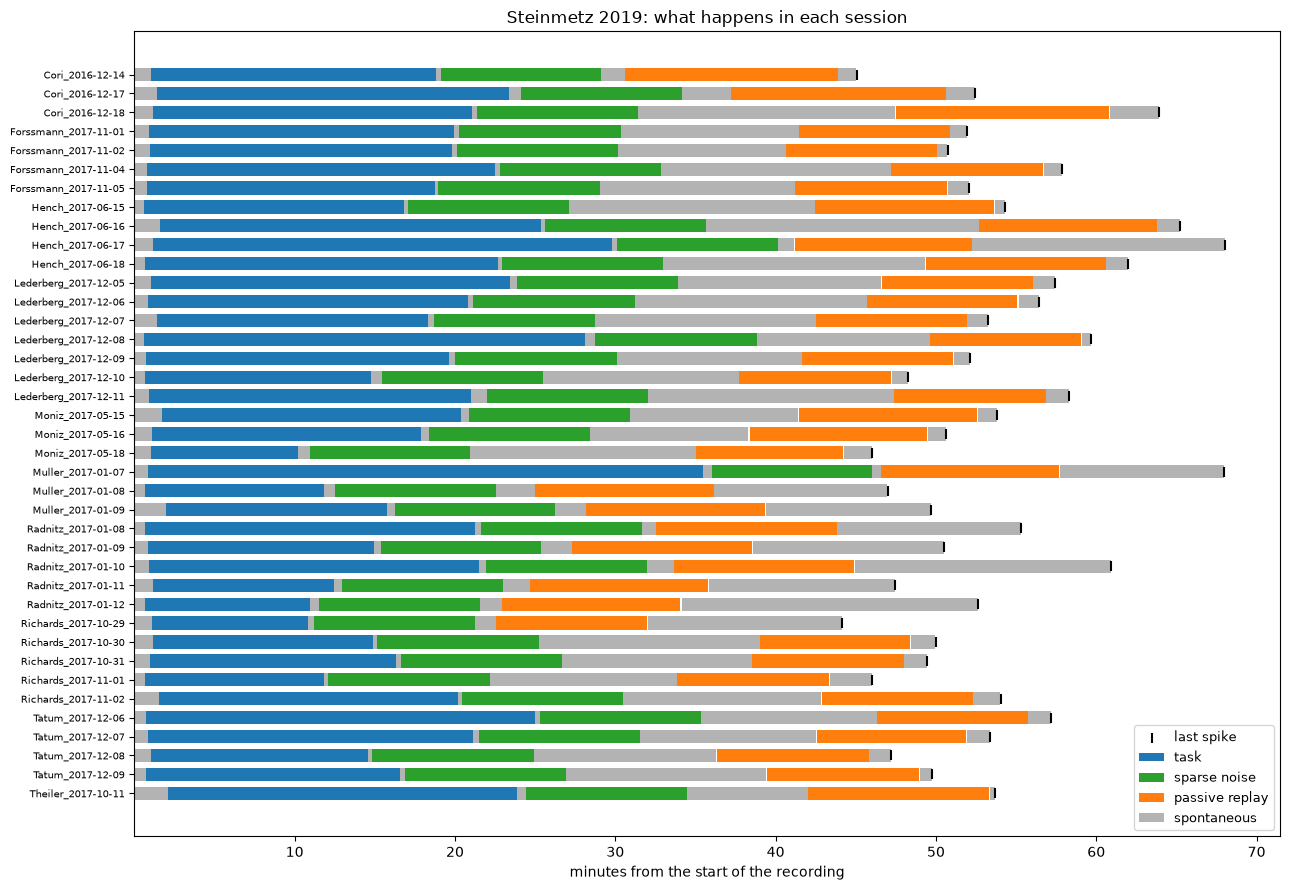

epoch,passive replay,sparse noise,spontaneous,task
minutes per session,,,,
min,9.2,10.0,3.9,9.2
50%,9.5,10.1,14.7,18.7
max,13.4,10.1,21.0,34.6


,sparse_noise,passiveVisual_n,passiveBeeps_n,passiveValveClick_n,passiveWhiteNoise_n
presentations per session,,,,,
min,7962,70,20,0,20
50%,12836,110,20,20,20
max,13163,150,25,25,25


In [4]:
EPOCH_COLOR = {"task": "C0", "sparse noise": "C2", "passive replay": "C1", "spontaneous": "0.7"}
order = sessions.session.tolist()[::-1]
fig, ax = plt.subplots(figsize=(13, 9))
for e, color in EPOCH_COLOR.items():
    d = epochs[epochs.epoch == e]
    ax.barh(d.session.map({s: i for i, s in enumerate(order)}), (d.end - d.start) / 60, left=d.start / 60, height=0.7,
            color=color, label=e)
ax.scatter(sessions.t_last / 60, sessions.session.map({s: i for i, s in enumerate(order)}), marker="|", color="k", s=60,
           label="last spike")
ax.set(yticks=range(len(order)), yticklabels=order, xlabel="minutes from the start of the recording",
       title="Steinmetz 2019: what happens in each session")
ax.tick_params(axis="y", labelsize=7.5)
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_session_timeline.png", dpi=150)
plt.show()
dur = epochs.assign(min=(epochs.end - epochs.start) / 60).groupby(["session", "epoch"])["min"].sum().unstack()
display(dur.describe().loc[["min", "50%", "max"]].round(1).rename_axis("minutes per session"))
display(sessions[["sparse_noise", "passiveVisual_n", "passiveBeeps_n", "passiveValveClick_n", "passiveWhiteNoise_n"]]
        .describe().loc[["min", "50%", "max"]].astype(int).rename_axis("presentations per session"))

## 2. What is in the release

- **Release**: figshare [9598406](https://doi.org/10.6084/m9.figshare.9598406) "Dataset from Steinmetz et al, 2019"
  (**CC BY 4.0**), the data of Steinmetz, Zatka-Haas, Carandini, Harris 2019, *Distributed coding of choice, action
  and engagement across the mouse brain*, Nature 576:266 ([10.1038/s41586-019-1787-x](https://doi.org/10.1038/s41586-019-1787-x)).
  One 8.9 GB zip with a tar per session, in ALF format (one `.npy` / `.tsv` per variable, documented in the
  [data wiki](https://github.com/nsteinme/steinmetz-et-al-2019/wiki/data-files)).
- **39 sessions from 10 mice**, **1–3 Neuropixels Phase 3A probes recorded at once** (92 insertions), all in the left
  hemisphere: visual and frontal cortex, hippocampus, striatum, thalamus, midbrain.
- **Units** are Kilosort clusters curated by hand in phy. `_phy_annotation`: 1 = multi-unit (not analysed in the paper),
  2 = good, 3 = unsorted; the wiki says to use ≥ 2. Noise clusters were removed before release.
- **Companion items**, not downloaded: face (40 Hz) and eye (100 Hz) videos (figshare
  [9702302](https://doi.org/10.6084/m9.figshare.9702302), 253.0 GB) and LFP (figshare
  [9727895](https://doi.org/10.6084/m9.figshare.9727895), 577.4 GB). The 30 kHz AP-band voltage is not public.
  Repackagings of the same data: ONE (figshare 9974357, 8.9 GB) and NWB (DANDI 000017, 14.7 GB).

| ALF object | What | Used for |
|---|---|---|
| `spikes` | times, cluster, amplitude, depth of every spike | NEURONS, LENGTH, raster |
| `clusters` | phy annotation, depth, peak channel, probe, template waveform | NEURONS, regions |
| `channels`, `probes` | CCF position and label of every channel; probe insertion and raw file name | regions, probe figure |
| `trials` | contrasts, stimulus / go cue / response / feedback times, choice, feedback, `included`, `repNum` | TRIALS, conditions |
| `wheel`, `wheelMoves` | wheel position (2.5 kHz encoder ticks), detected movements | behaviour labels |
| `face`, `eye`, `licks`, `lickPiezo` | face motion energy (40 Hz), pupil area / position (100 Hz), lick times, lick sensor (500 Hz) | behaviour labels |
| `sparseNoise`, `passive*`, `spontaneous` | receptive-field mapping squares, passive replay stimuli, grey-screen periods | session timeline |

**Data quirks.**
- `clusters.peakChannel` is 1-based and counts the channels of all of the session's probes; the extract subtracts 1
  and checks that the channel's probe is the unit's probe.
- CCF left-right follows the allenCCF toolbox: **high LR = right**. Every channel lies left of the midline (5,700 µm)
  except 656 of 26,710 in midline structures (septum, olfactory, medial prefrontal), up to 650 µm across.
- Channels the authors placed outside the brain are labelled `root` (7,698 channels; 4,305 good units).
- `trials.included` applies the paper's disengagement rule (a miss after two misses; NoGos at the end of the session),
  not its reaction-time rule (wiki).
- `eye.blink` exists in only 2 sessions. `Moniz_2017-05-15` stores its 25 passive valve-click times as NaN.
- Two sessions lack some conditions (`Radnitz_2017-01-11` has 14 of the 16, `Theiler_2017-10-11` 13).

**Checks.** Units, probes and trials add up across tables. The paper reports 10 mice, 39 sessions, 92 insertions,
29,134 neurons (747 ± 38 per session, mean ± s.e.), 22,458 of them in 42 regions, and 9,538 trials (Fig. 1c).

In [5]:
assert len(sessions) == 39 and sessions.mouse.nunique() == 10 and len(probes) == 92
assert probes.groupby("session").units.sum().reindex(sessions.session).tolist() == sessions.units.tolist()
assert (good.groupby("session").size().reindex(sessions.session).to_numpy() == sessions.good_units).all()
assert trials.groupby("session").size().reindex(sessions.session).tolist() == sessions.trials.tolist()
assert set(zip(trials.contrast_left, trials.contrast_right)) == {(l, r) for l in CONTRASTS for r in CONTRASTS}
inb = good[good.acronym != "root"]
se = sessions.good_units.std() / np.sqrt(len(sessions))
print(f"good units {len(good):,}, {sessions.good_units.mean():.0f} ± {se:.0f} per session (paper 29,134, 747 ± 38); "
      f"not on root channels {len(inb):,}; of those, firing > 0.05 spikes/s {(inb.rate_hz > 0.05).sum():,}")
print(f"included trials {trials.included.sum():,} (paper Fig. 1c: 9,538); probes {len(probes)} (paper 92)")
raw = release[release.counted_in_raw]
display(release.groupby(["item", "article", "license", "counted_in_raw"]).size_bytes.agg(files="count", GB="sum")
        .assign(GB=lambda d: (d.GB / GB).round(3)))

good units 33,997, 872 ± 46 per session (paper 29,134, 747 ± 38); not on root channels 29,692; of those, firing > 0.05 spikes/s 29,152
included trials 9,538 (paper Fig. 1c: 9,538); probes 92 (paper 92)


,,,,files,GB
item,article,license,counted_in_raw,,
lfp,9727895,CC BY 4.0,True,39,577.392
nwb_repackaging,11274968,CC BY 4.0,False,39,14.682
one_repackaging,9974357,CC BY 4.0,False,1,8.860
spikes_behaviour,9598406,CC BY 4.0,True,2,8.863
videos,9702302,CC BY 4.0,True,39,253.048


## 3. How those files become spreadsheet numbers

- **SUBJECTS**: mice, 10.
- **TRIALS**: every task trial (`trials.*`, all choices and outcomes, repeats included). `included` (engaged)
  trials and the other breakdowns go in NOTES. Passive replay presentations are not trials.
- **NEURONS**: clusters with `_phy_annotation` ≥ 2 (good + unsorted, the wiki's rule). TOTAL = sum; MEDIAN = per
  session (all probes of a session are simultaneous). All clusters, those not on `root` channels, and the paper's count
  go in NOTES.
- **CHANNELS**: `N/A` (sorted units).
- **LENGTH**: first to last spike of each session, summed. Spikes cover the whole session (task, sparse noise,
  passive replay, spontaneous); task time alone goes in NOTES.
- **RAW**: every file of the three figshare items: spikes + behaviour (8.9 GB), videos (253.0 GB) and LFP (577.4 GB).
  The repackagings are not counted.
- **BENCHMARK**: what a spiking benchmark needs, at its in-memory size: good-unit spike times and cluster ids
  (float64 + int32, 12 bytes per spike), the trials, wheel and wheel movements, face motion energy, eye tracking, lick
  times, the passive / sparse-noise / spontaneous tables, and cluster / channel / probe metadata. Left out: multi-unit
  spikes, spike amplitudes and depths, template waveforms, the raw lick sensor and the LFP timestamps.

In [6]:
def component(f):
    obj = f.split(".")[0]
    if ".imec.lf." in f:
        return "LFP timestamps (left out)"
    if obj in ("trials",):
        return "trials"
    if obj in ("wheel", "wheelMoves"):
        return "wheel"
    if obj in ("face", "eye", "licks"):
        return {"face": "face motion energy", "eye": "eye tracking", "licks": "lick times"}[obj]
    if obj.startswith("passive") or obj in ("sparseNoise", "spontaneous"):
        return "passive / sparse noise / spontaneous"
    if f.startswith("clusters.template"):
        return "template waveforms (left out)"
    if obj in ("clusters", "channels", "probes"):
        return "cluster / channel / probe metadata"
    if obj == "lickPiezo":
        return "raw lick sensor (left out)"
    if f in ("spikes.amps.npy", "spikes.depths.npy"):
        return "spike amplitudes + depths (left out)"
    if f in ("spikes.times.npy", "spikes.clusters.npy"):
        return "spikes (all clusters; good counted separately)"
    raise ValueError(f)


files["component"] = files.file.map(component)
comp = files.groupby("component").nbytes.sum()
spike_bytes = sessions.good_spike_bytes.sum()
kept = comp.drop([c for c in comp.index if "left out" in c or c.startswith("spikes")])
benchmark_bytes = spike_bytes + kept.sum()
raw_bytes = raw.size_bytes.sum()
summary = pd.Series({
    "subjects": sessions.mouse.nunique(), "sessions": len(sessions), "trials": len(trials),
    "  included (engaged)": int(trials.included.sum()),
    "total neurons (annotation ≥ 2)": sessions.good_units.sum(), "median neurons": sessions.good_units.median(),
    "  not on root channels": sessions.good_in_brain.sum(), "all clusters": sessions.units.sum(),
    "length (min)": round(sessions.length_min.sum(), 1), "  task (min)": round(sessions.task_min.sum(), 1),
    "raw (GB)": round(raw_bytes / GB, 3), "benchmark (GB)": round(benchmark_bytes / GB, 3),
    "  good-unit spikes (GB)": round(spike_bytes / GB, 3),
    **{f"  {c} (GB)": round(b / GB, 3) for c, b in kept.sort_values(ascending=False).items()}})
display(summary.to_frame("value"))
print("left out (GB):", {c: round(b / GB, 3) for c, b in comp.items() if "left out" in c or c.startswith("spikes")},
      f"; multi-unit spikes {(sessions.all_spike_bytes - sessions.good_spike_bytes).sum() / GB:.3f} GB")
print(f"the wheel is stored at {sessions.wheel_hz.median():.0f} Hz ({comp['wheel'] / GB:.2f} GB); "
      f"at 100 Hz it would be {comp['wheel'] / GB / 25:.2f} GB")

,value
subjects,10.000
sessions,39.000
trials,10050.000
included (engaged),9538.000
total neurons (annotation ≥ 2),33997.000
median neurons,795.000
not on root channels,29692.000
all clusters,48661.000
length (min),2096.300
task (min),712.900


left out (GB): {'LFP timestamps (left out)': 0.0, 'raw lick sensor (left out)': 0.497, 'spike amplitudes + depths (left out)': 5.972, 'spikes (all clusters; good counted separately)': 5.304, 'template waveforms (left out)': 1.616} ; multi-unit spikes 0.918 GB
the wheel is stored at 2500 Hz (2.49 GB); at 100 Hz it would be 0.10 GB


## 4. Figures

### Probes in the brain

Every probe, drawn through its channels' CCF positions (`steinmetz_probes.png`, rendered with brainrender outside
this notebook from `channels.parquet`). The paper's own track figure is Fig. 1h (shown with Fig. 1i under Brain regions).

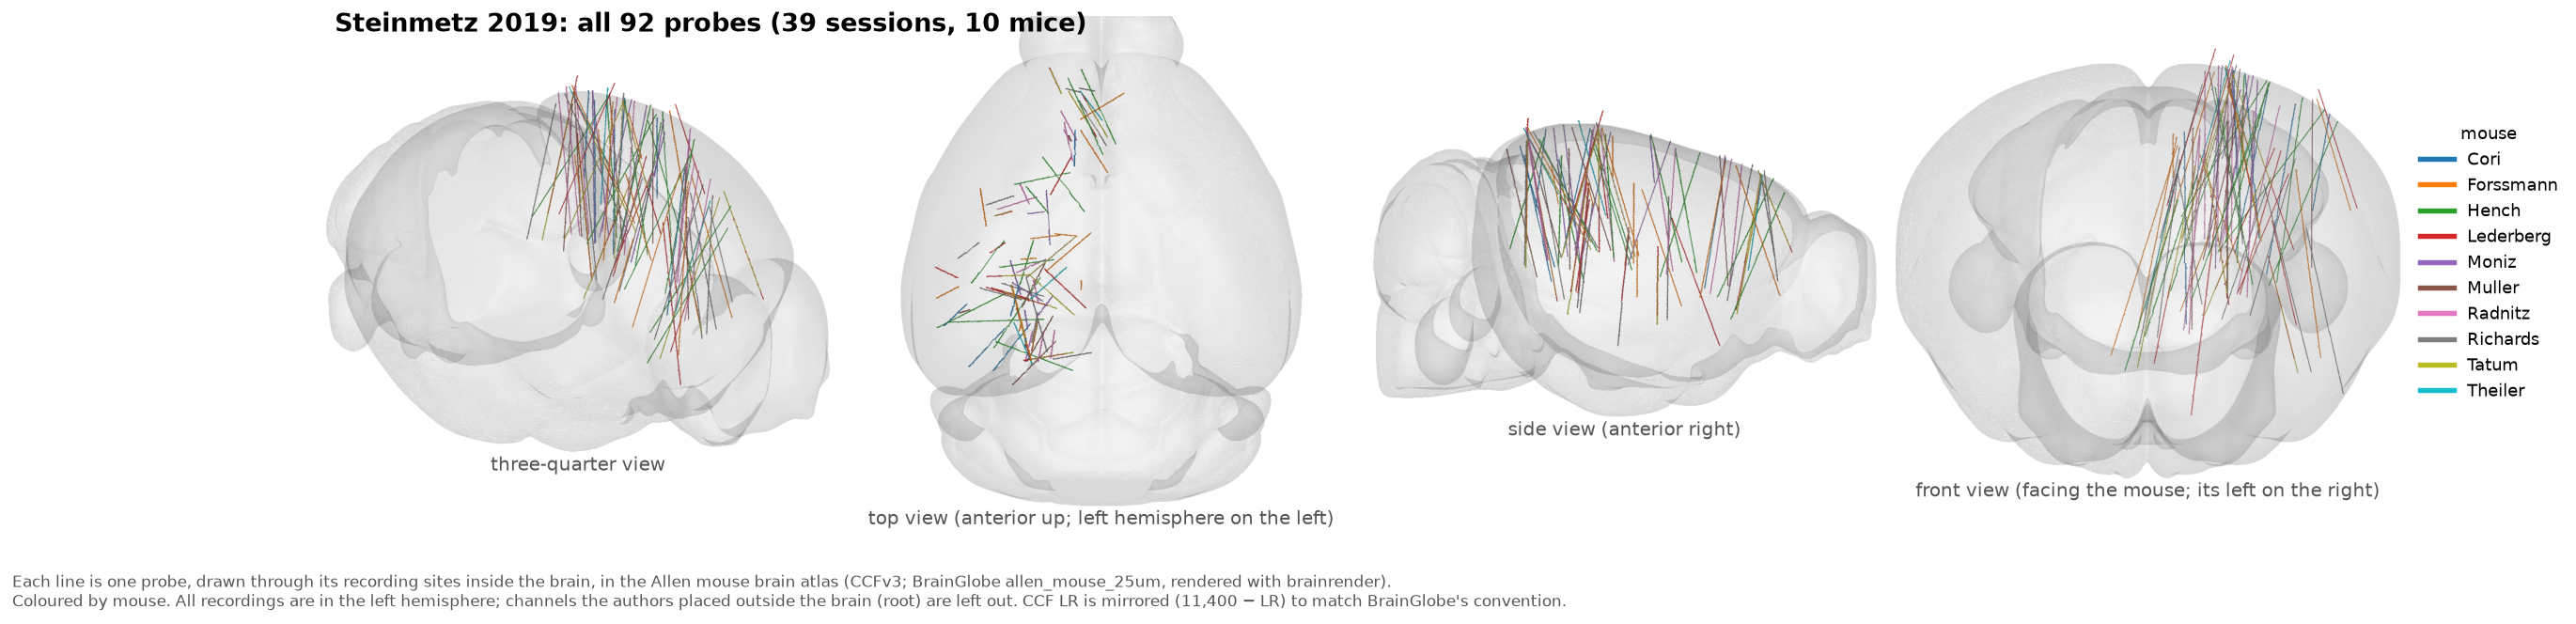

probes per session,1,2,3
sessions,1,23,15


probe name (raw file),K3,K1,K2,M2,V1,PM,AM,LM,M1,S1,A,RSP
probes,24,22,18,6,6,4,4,2,2,2,1,1


In [7]:
display(Image(filename=str(FIGURE_DIR / "steinmetz_probes.png")))
display(sessions.probes.value_counts().sort_index().rename_axis("probes per session").to_frame("sessions").T)
display(probes.probe_name.value_counts().head(15).rename_axis("probe name (raw file)").to_frame("probes").T)

### Neurons per session

Sessions by how many units they have (sum over probes): all clusters and units with annotation ≥ 2.

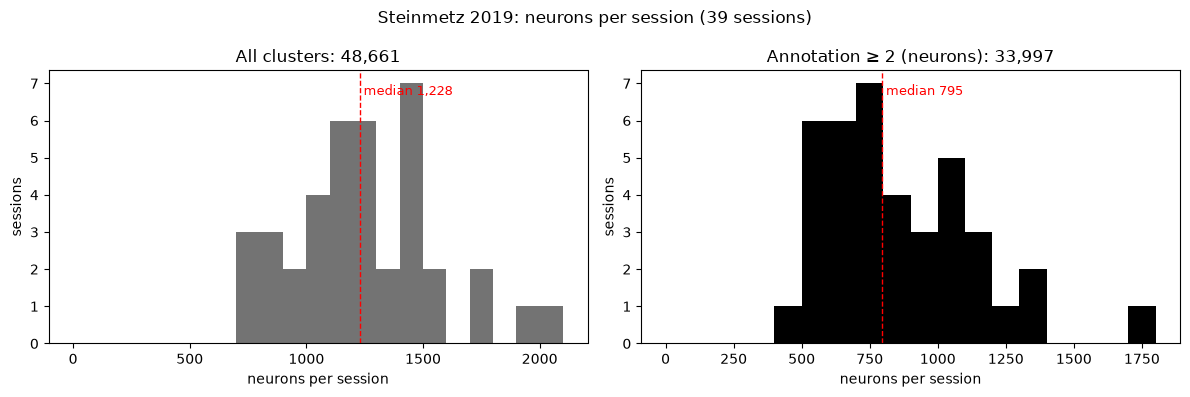

In [8]:
def median_line(ax, values, color="k"):
    m = float(np.median(values))
    ax.axvline(m, color=color, ls="--", lw=1)
    ax.text(m, ax.get_ylim()[1] * 0.95, f" median {m:,.0f}", color=color, va="top", fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, color, name, bins in [(axes[0], "units", "0.45", "All clusters", np.arange(0, 2200, 100)),
                                   (axes[1], "good_units", "k", "Annotation ≥ 2 (neurons)", np.arange(0, 1900, 100))]:
    ax.hist(sessions[col], bins=bins, color=color)
    ax.set(title=f"{name}: {sessions[col].sum():,}", xlabel="neurons per session", ylabel="sessions")
    median_line(ax, sessions[col], "r")
fig.suptitle(f"Steinmetz 2019: neurons per session ({len(sessions)} sessions)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_neurons_per_session.png", dpi=150)
plt.show()

### Firing rates

One rate per neuron: its spikes over its session's first-to-last spike (LENGTH above). Rates over the task alone are
printed too.

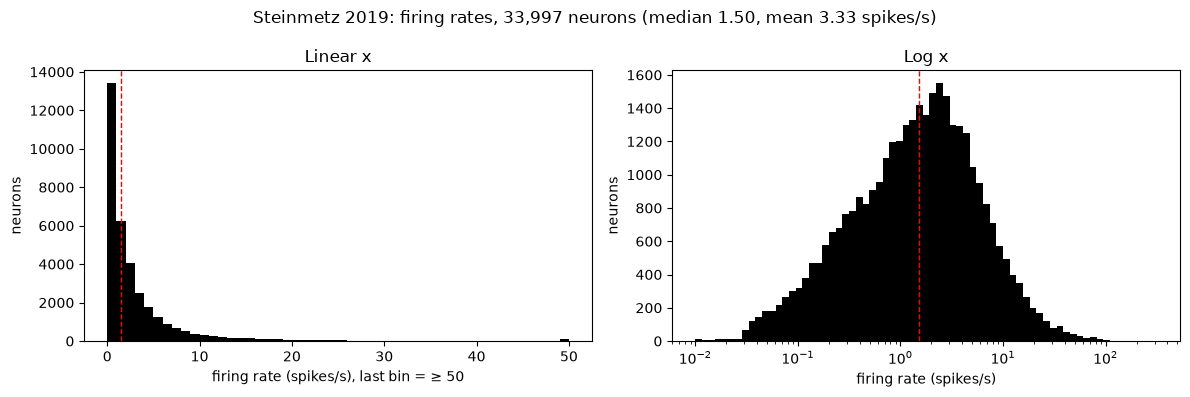

over the task only: median 1.23, mean 3.43 spikes/s


In [9]:
fr = good.rate_hz
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fr.clip(upper=50), bins=np.arange(0, 51, 1), color="k")
axes[0].set(xlabel="firing rate (spikes/s), last bin = ≥ 50", ylabel="neurons", title="Linear x")
axes[1].hist(fr[fr > 0], bins=np.logspace(-2, 2.5, 70), color="k")
axes[1].set(xscale="log", xlabel="firing rate (spikes/s)", ylabel="neurons", title="Log x")
for ax in axes:
    ax.axvline(fr.median(), color="r", ls="--", lw=1)
fig.suptitle(f"Steinmetz 2019: firing rates, {len(fr):,} neurons (median {fr.median():.2f}, mean {fr.mean():.2f} spikes/s)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_firing_rates.png", dpi=150)
plt.show()
print(f"over the task only: median {good.rate_task_hz.median():.2f}, mean {good.rate_task_hz.mean():.2f} spikes/s")

### Trials per session

Sessions by trial count: all trials (filled) and `included` (engaged) trials (outline).

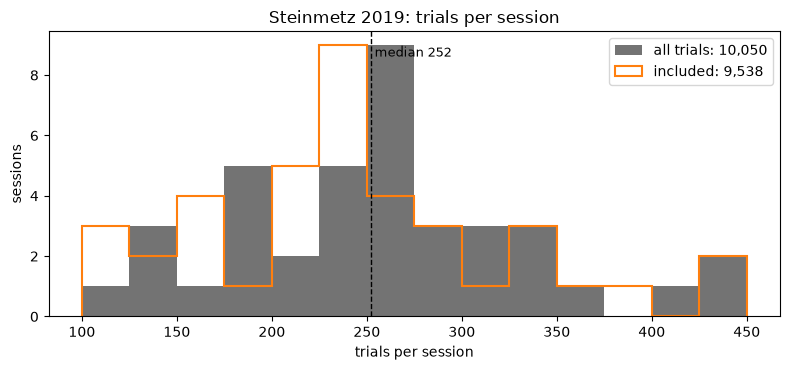

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(100, sessions.trials.max() + 25, 25)
ax.hist(sessions.trials, bins=bins, color="0.45", label=f"all trials: {sessions.trials.sum():,}")
ax.hist(sessions.included, bins=bins, histtype="step", color="C1", lw=1.5, label=f"included: {sessions.included.sum():,}")
ax.set(xlabel="trials per session", ylabel="sessions", title="Steinmetz 2019: trials per session")
ax.legend()
median_line(ax, sessions.trials)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_trials_per_session.png", dpi=150)
plt.show()

### Trials by condition

- **Condition**: (left contrast, right contrast), 16 pairs. The first table counts trials over all sessions.
- **Correct response**: left choice, right choice, NoGo, or either (equal non-zero contrasts, rewarded at random).
- **Choice**: what the mouse did. **Feedback**: reward (+1) or white noise (−1).
- **Included**: not in a disengaged stretch. **Repeat**: `repNum` > 1 (an easy condition repeated after a mistake).
- **% per session**: median [min – max] over sessions of that category's share of the session's trials.

In [11]:
def mix_table(col, order):
    table = pd.crosstab(trials.session, trials[col]).reindex(columns=order, fill_value=0)
    share = table.div(table.sum(axis=1), axis=0) * 100
    return pd.DataFrame({
        "trials": table.sum().to_numpy(),
        "% of trials": (table.sum() / len(trials) * 100).round(1).to_numpy(),
        "% per session": [f"{share[c].median():.1f} [{share[c].min():.1f} – {share[c].max():.1f}]" for c in order],
    }, index=order).rename_axis(col)


grid = pd.crosstab(trials.contrast_left * 100, trials.contrast_right * 100).sort_index(ascending=False)
display(grid.rename_axis(index="left contrast (%)", columns="right contrast (%)"))
trials["feedback"] = trials.feedback_type.map({1: "reward", -1: "white noise"})
trials["engaged"] = np.where(trials.included, "included", "excluded")
trials["repeat"] = np.where(trials.rep_num > 1, "repeat", "first")
for col, order in [("correct_response", ["left choice", "right choice", "NoGo", "either (50 %)"]),
                   ("choice_name", ["left choice", "right choice", "NoGo"]), ("feedback", ["reward", "white noise"]),
                   ("engaged", ["included", "excluded"]), ("repeat", ["first", "repeat"])]:
    display(mix_table(col, order))
display(pd.crosstab(trials.correct_response, trials.choice_name, margins=True))
cond = trials.groupby(["session", "condition"]).size()
first = trials[trials.rep_num == 1].groupby(["session", "condition"]).size()
print(f"trials per condition per session (16 conditions): median {cond.median():.0f} ({cond.min()}–{cond.max()}); "
      f"without repeats: median {first.median():.0f} ({first.min()}–{first.max()}); sessions missing a condition: "
      f"{(cond.groupby('session').size() < 16).sum()} (14 and 13 of 16)")

right contrast (%),0.0,25.0,50.0,100.0
left contrast (%),,,,
100.0,944,797,322,221
50.0,737,318,226,295
25.0,323,225,342,670
0.0,2649,348,688,945


,trials,% of trials,% per session
correct_response,,,
left choice,3441,34.2,34.3 [20.2 – 49.7]
right choice,3288,32.7,32.2 [23.4 – 44.4]
NoGo,2649,26.4,25.1 [16.4 – 42.3]
either (50 %),672,6.7,6.7 [0.0 – 18.7]


,trials,% of trials,% per session
choice_name,,,
left choice,3372,33.6,33.5 [20.5 – 45.7]
right choice,3373,33.6,34.2 [18.2 – 46.0]
NoGo,3305,32.9,33.8 [18.7 – 55.9]


,trials,% of trials,% per session
feedback,,,
reward,6923,68.9,67.5 [50.3 – 83.0]
white noise,3127,31.1,32.5 [17.0 – 49.7]


,trials,% of trials,% per session
engaged,,,
included,9538,94.9,95.0 [84.6 – 99.3]
excluded,512,5.1,5.0 [0.7 – 15.4]


,trials,% of trials,% per session
repeat,,,
first,8301,82.6,80.9 [70.6 – 92.1]
repeat,1749,17.4,19.1 [7.9 – 29.4]


choice_name,NoGo,left choice,right choice,All
correct_response,,,,
NoGo,1768,345,536,2649
either (50 %),114,303,255,672
left choice,765,2477,199,3441
right choice,658,247,2383,3288
All,3305,3372,3373,10050


trials per condition per session (16 conditions): median 11 (1–154); without repeats: median 10 (1–86); sessions missing a condition: 2 (14 and 13 of 16)


### Trials × neurons

Each cell counts sessions with that many trials (x) and neurons (y). Top: number of sessions. Bottom: % of sessions.
Columns: all clusters, neurons (annotation ≥ 2).

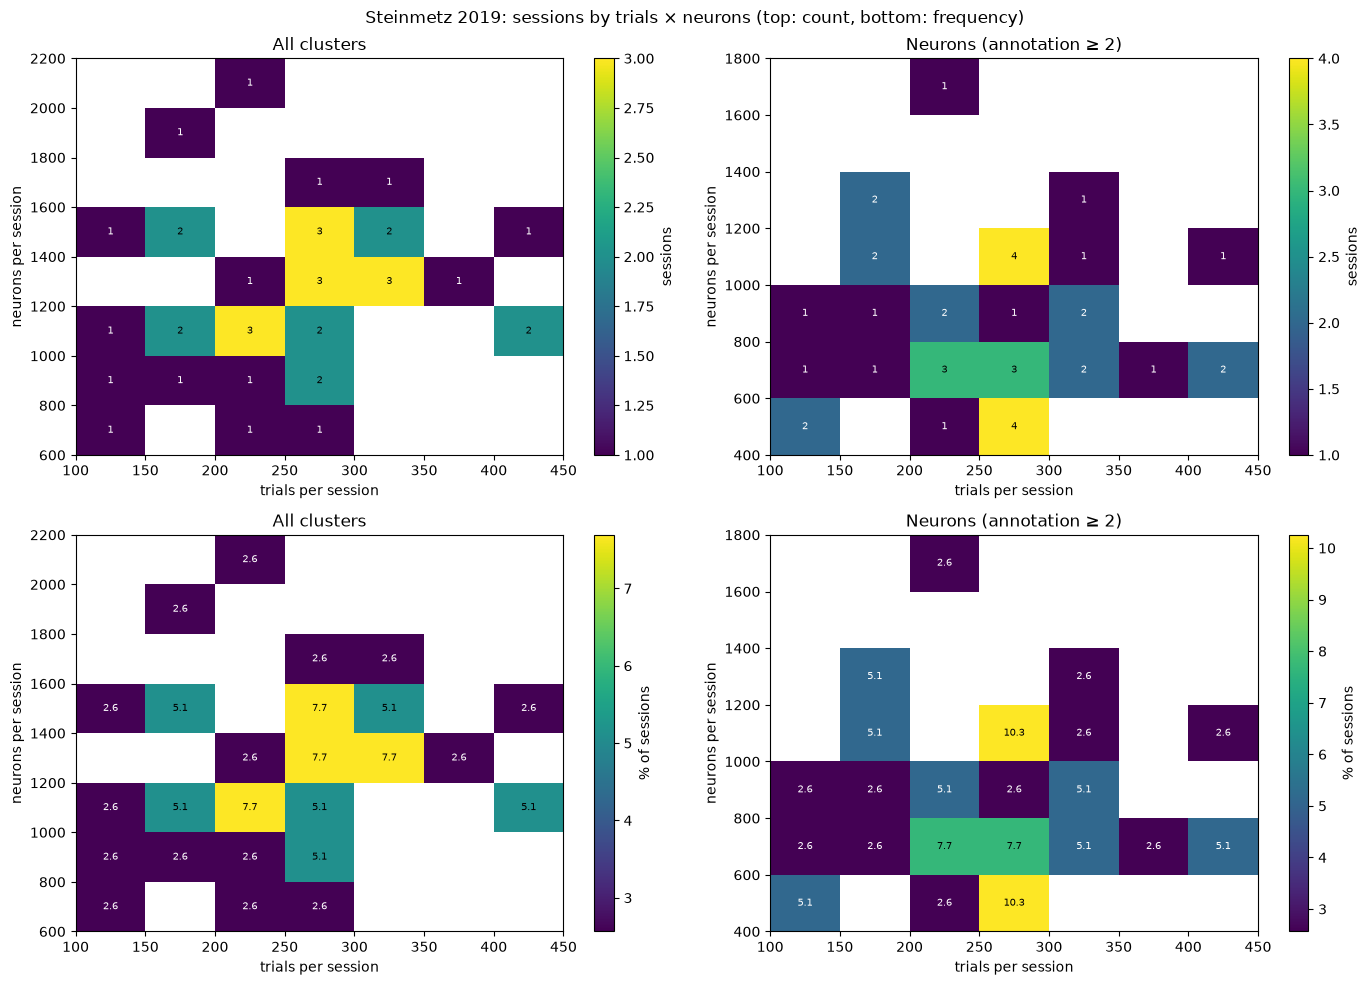

In [12]:
def heatmap(ax, x, y, xbins, ybins, percent, title):
    H, xe, ye = np.histogram2d(x, y, [xbins, ybins])
    if percent:
        H = H / len(x) * 100
    im = ax.pcolormesh(xe, ye, np.ma.masked_equal(H.T, 0), cmap="viridis", shading="flat")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            if H[i, j]:
                ax.text((xe[i] + xe[i + 1]) / 2, (ye[j] + ye[j + 1]) / 2, f"{H[i, j]:.1f}" if percent else f"{H[i, j]:.0f}",
                        ha="center", va="center", fontsize=7, color="w" if H[i, j] < 0.6 * H.max() else "k")
    ax.set(title=title, xlabel="trials per session", ylabel="neurons per session")
    plt.colorbar(im, ax=ax, label="% of sessions" if percent else "sessions")


tbins = np.arange(100, sessions.trials.max() + 50, 50)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, percent in enumerate([False, True]):
    heatmap(axes[row, 0], sessions.trials, sessions.units, tbins, np.arange(600, sessions.units.max() + 200, 200),
            percent, "All clusters")
    heatmap(axes[row, 1], sessions.trials, sessions.good_units, tbins,
            np.arange(400, sessions.good_units.max() + 200, 200), percent, "Neurons (annotation ≥ 2)")
fig.suptitle("Steinmetz 2019: sessions by trials × neurons (top: count, bottom: frequency)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_trials_x_neurons.png", dpi=150)
plt.show()

### Brain regions

Each unit takes the CCF label of its peak channel (`channels.brainLocation.tsv`, from the authors' histology
alignment), mapped to its region (layers merged into their parent) and major division (the same mapping as the other
datasets). "outside" = channels labelled `root`. Left: neurons by division. Right: the 30 regions with the most
neurons. The paper groups its neurons into 42 regions (Fig. 1i, below, with the number of neurons per region).

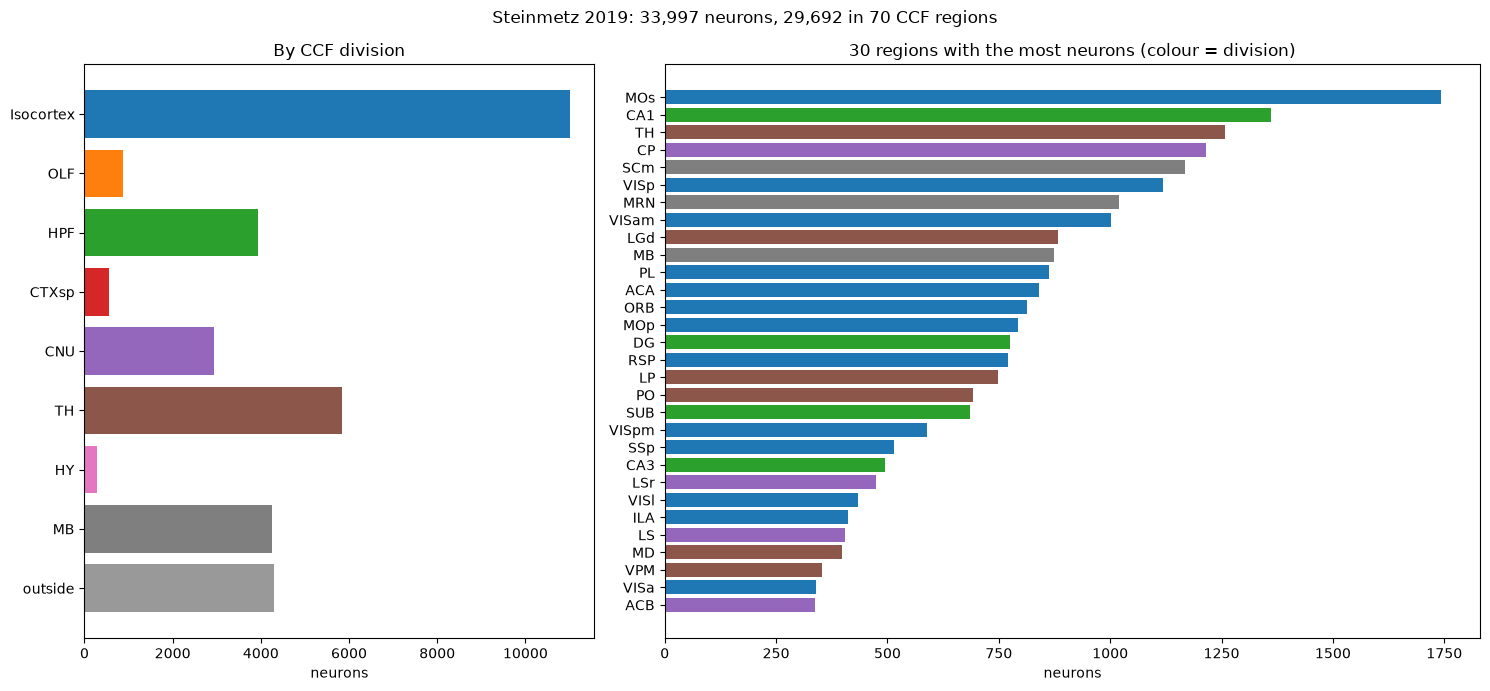

73 CCF labels -> 70 regions (layers merged); 53 regions with ≥ 100 neurons. Per session: median 7 regions with ≥ 20 neurons.


division,Isocortex,OLF,HPF,CTXsp,CNU,TH,HY,MB,HB,CB
sessions with ≥ 20 neurons,33,7,27,5,17,27,3,19,0,0


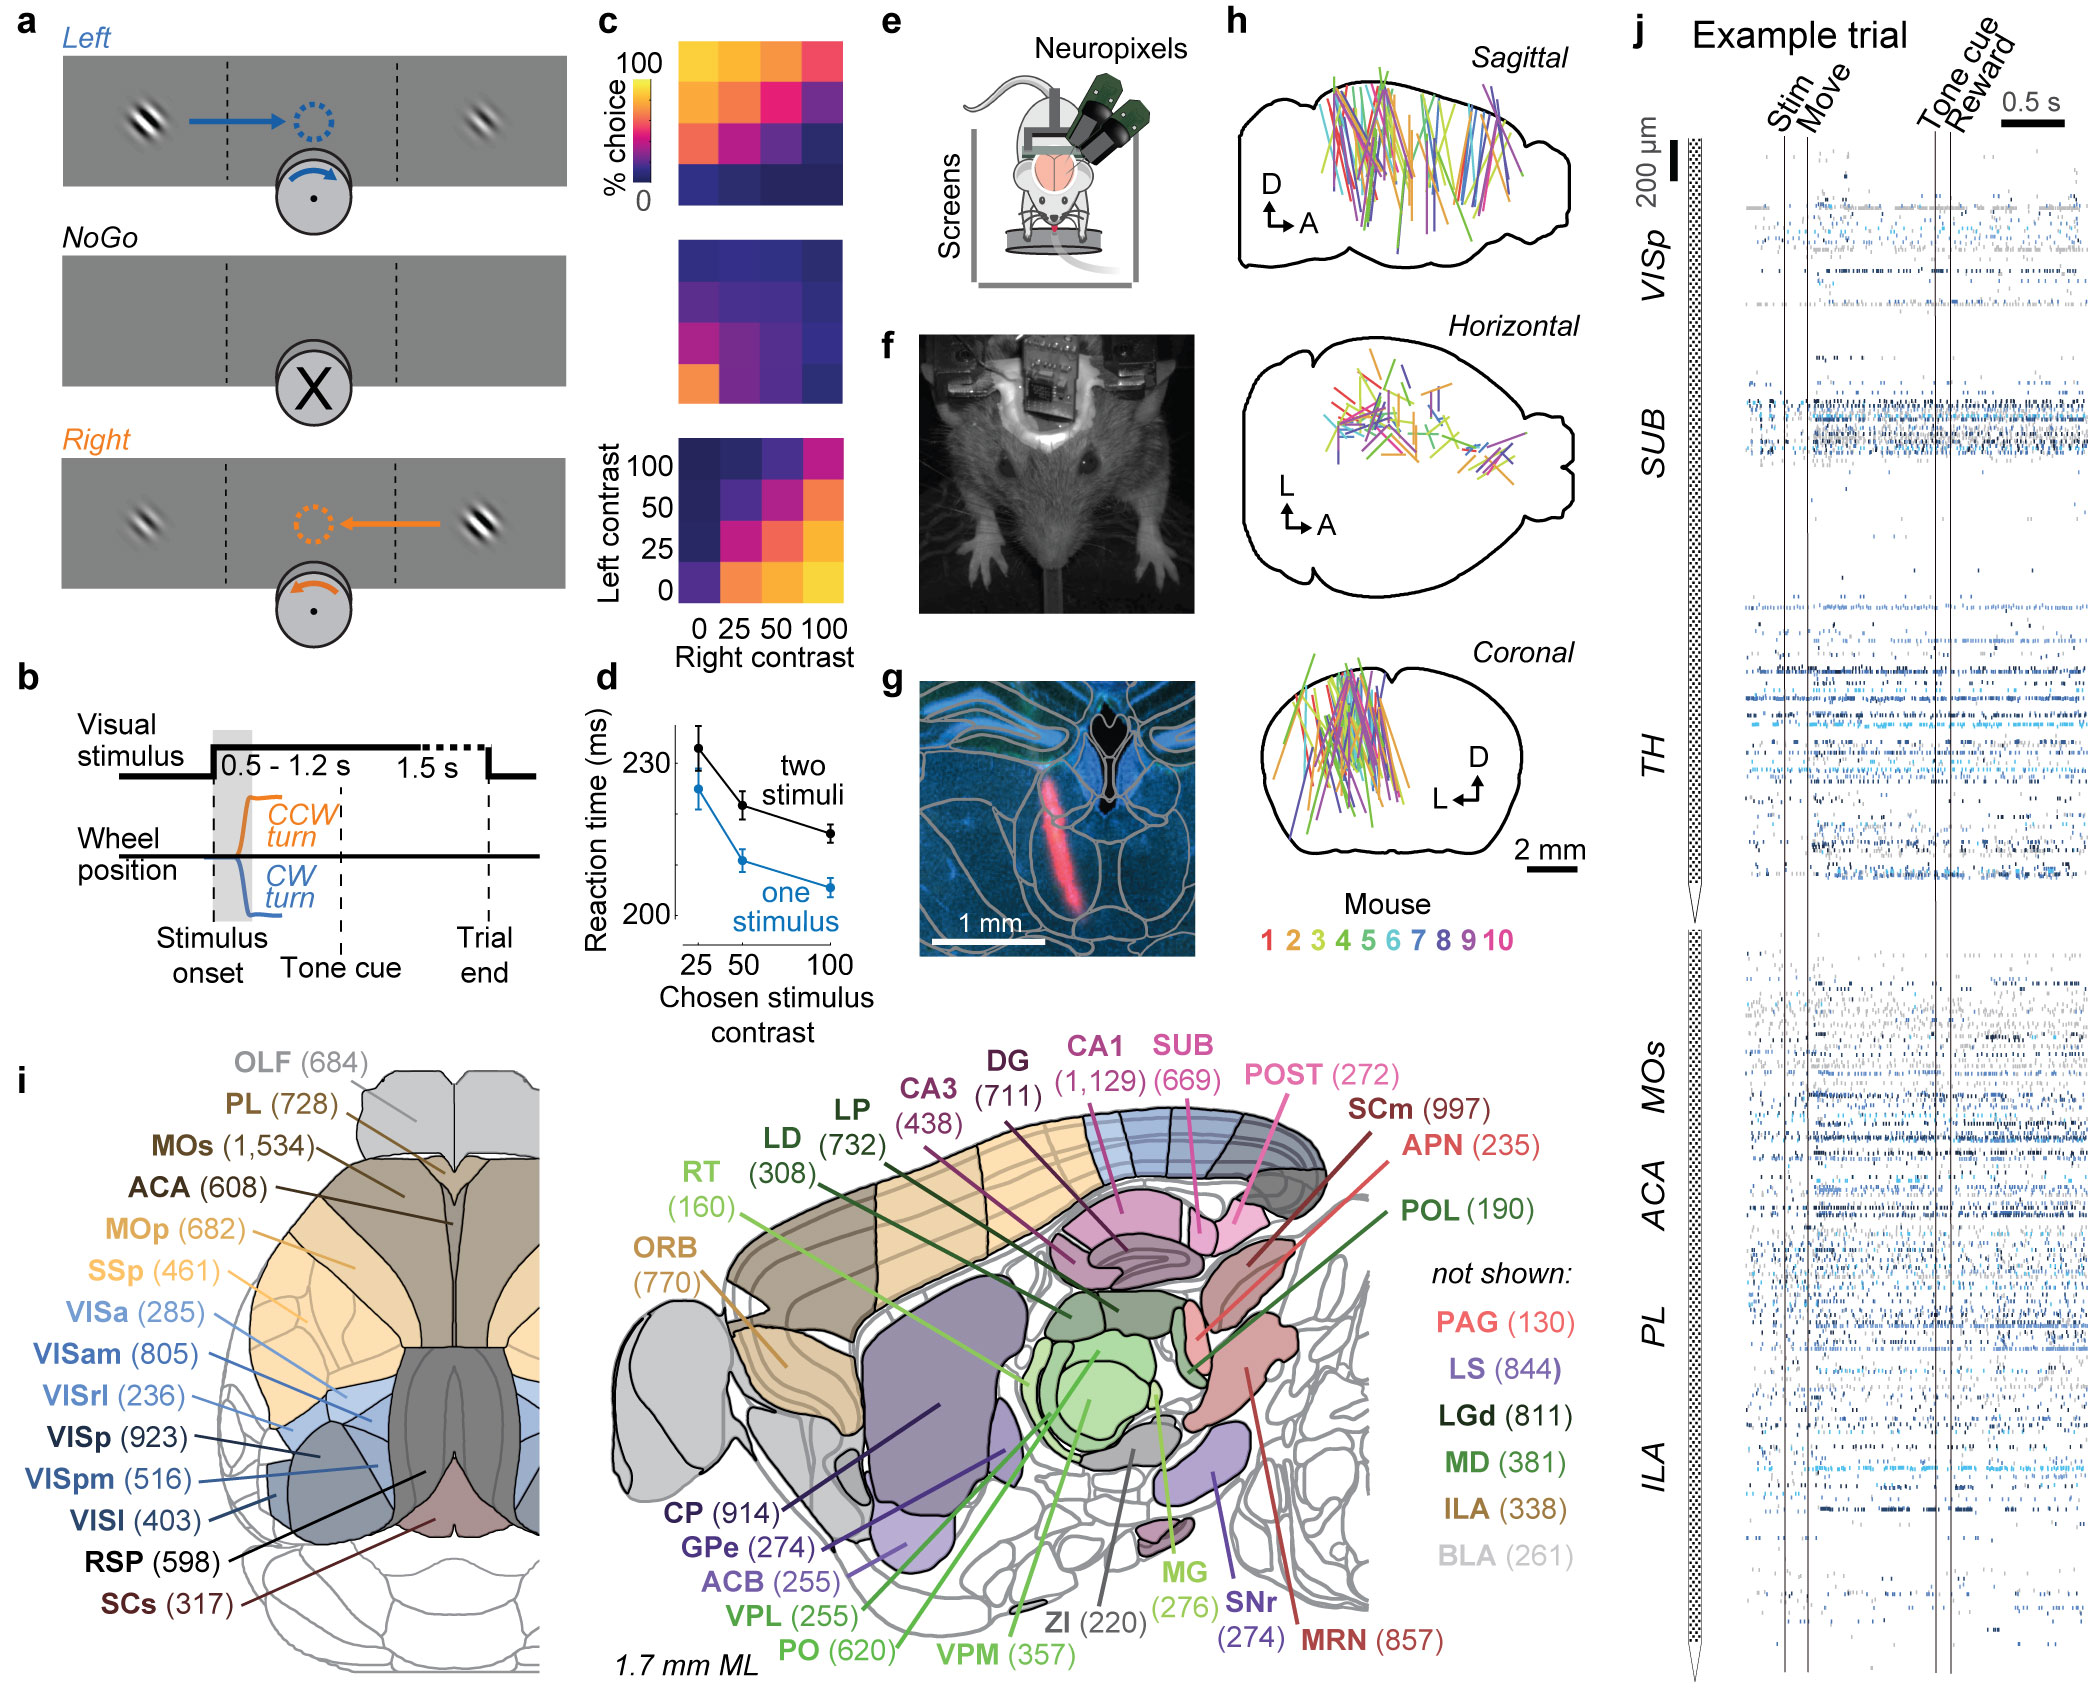

In [13]:
DIVS = ["Isocortex", "OLF", "HPF", "CTXsp", "CNU", "TH", "HY", "MB", "HB", "CB"]
DIV_COLOR = dict(zip(DIVS + ["outside"], plt.cm.tab10.colors + ((0.6, 0.6, 0.6),)))
div = good.division.replace("", "outside").value_counts().reindex(DIVS + ["outside"]).dropna()
reg = good[good.region != ""].groupby(["region", "division"]).size().sort_values(ascending=False)
top = reg.head(30)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw=dict(width_ratios=[1, 1.6]))
axes[0].barh(np.arange(len(div))[::-1], div, color=[DIV_COLOR[d] for d in div.index])
axes[0].set(yticks=np.arange(len(div))[::-1], yticklabels=div.index, xlabel="neurons", title="By CCF division")
axes[1].barh(np.arange(len(top))[::-1], top, color=[DIV_COLOR[d] for d in top.index.get_level_values(1)])
axes[1].set(yticks=np.arange(len(top))[::-1], yticklabels=top.index.get_level_values(0), xlabel="neurons",
            title="30 regions with the most neurons (colour = division)")
fig.suptitle(f"Steinmetz 2019: {len(good):,} neurons, {(good.region != '').sum():,} in {good[good.region != ''].region.nunique()} CCF regions")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "steinmetz_regions.png", dpi=150)
plt.show()
per = good[good.region != ""].groupby(["session", "region"]).size()
print(f"{good.acronym.nunique()} CCF labels -> {reg.index.get_level_values(0).nunique()} regions (layers merged); "
      f"{(reg >= 100).sum()} regions with ≥ 100 neurons. Per session: median "
      f"{(per >= 20).groupby('session').sum().median():.0f} regions with ≥ 20 neurons.")
div_sess = good[good.division != ""].groupby(["session", "division"]).size().unstack(fill_value=0)
display((div_sess >= 20).sum().reindex(DIVS).fillna(0).astype(int).rename("sessions with ≥ 20 neurons").to_frame().T)
display(Image(filename=str(FIGURE_DIR / "steinmetz_paper_fig1.jpg"), width=900))

### Raster

The session with the median number of neurons; 30 s starting 1 s before its 11th trial's stimulus. Rows = neurons,
grouped by probe and sorted by depth (deepest at the bottom of each band). Blue lines separate probes; the label is
the probe name and its most common regions. Green = stimulus onset (with left / right contrast), orange = go cue,
red = feedback (solid = reward, dotted = white noise). Below: wheel position, face motion energy and licks.

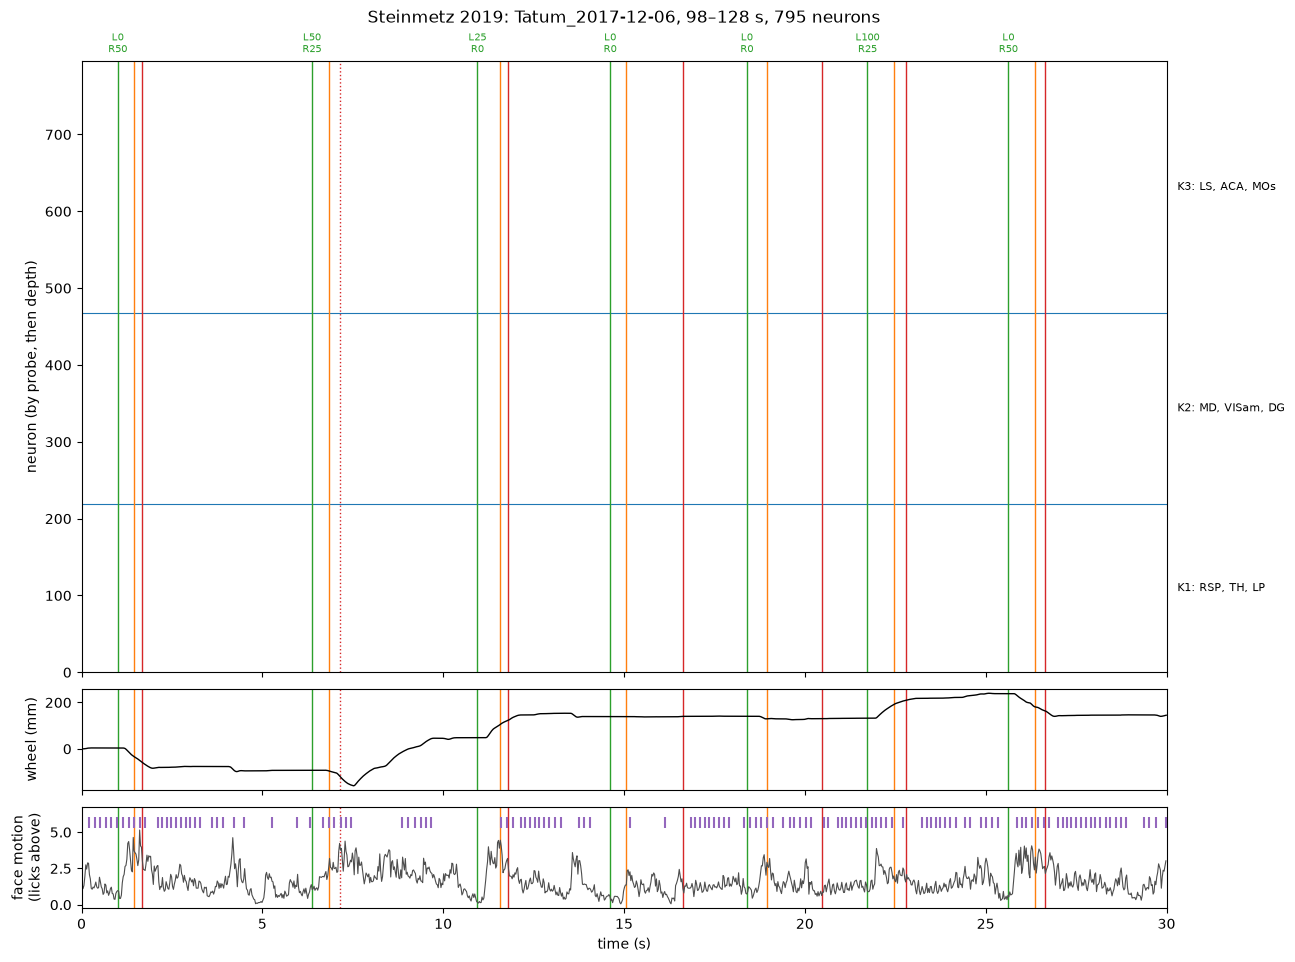

In [14]:
r = np.load(TABLES / "raster.npz", allow_pickle=True)
sess = str(r["session"])
fig, (ax, wx, fx) = plt.subplots(3, 1, figsize=(14, 11), sharex=True,
                                 gridspec_kw=dict(height_ratios=[6, 1, 1], hspace=0.06))
ax.scatter(r["spike_times"], r["spike_rows"], s=0.3, color="k", marker="|", linewidths=0.3, rasterized=True)
b = r["probe_bounds"]
for y in b[1:-1]:
    ax.axhline(y, color="C0", lw=0.8)
for k, name in enumerate(r["probe_names"]):
    regs = pd.Series(r["unit_regions"][b[k]:b[k + 1]])
    ax.text(30.3, (b[k] + b[k + 1]) / 2, f"{name}: {', '.join(regs[regs != ''].value_counts().head(3).index)}",
            va="center", fontsize=8)
for x in (ax, wx, fx):
    for t in r["trial_stim_time"]:
        x.axvline(t, color="C2", lw=1)
    for t in r["trial_go_cue_time"]:
        x.axvline(t, color="C1", lw=1)
    for t, f in zip(r["trial_feedback_time"], r["trial_feedback"]):
        x.axvline(t, color="C3", lw=1, ls="-" if f > 0 else ":")
for t, cl, cr in zip(r["trial_stim_time"], r["trial_contrast_left"], r["trial_contrast_right"]):
    if 0 <= t < 30:
        ax.text(t, b[-1] * 1.01, f"L{cl * 100:.0f}\nR{cr * 100:.0f}", color="C2", fontsize=7, ha="center", va="bottom")
ax.set(ylim=(0, b[-1]), ylabel="neuron (by probe, then depth)")
ax.set_title(f"Steinmetz 2019: {sess}, {float(r['t0']):.0f}–{float(r['t0']) + 30:.0f} s, {b[-1]:,} neurons", pad=28)
wx.plot(r["wheel_times"], r["wheel_mm"], color="k", lw=1)
wx.set(ylabel="wheel (mm)")
fx.plot(r["face_times"], r["face_motion"], color="0.3", lw=0.8)
fx.eventplot([r["lick_times"]], lineoffsets=[np.nanmax(r["face_motion"]) * 1.1], linelengths=np.nanmax(r["face_motion"]) * 0.15,
             colors="C4")
fx.set(ylabel="face motion\n(licks above)", xlabel="time (s)", xlim=(0, 30))
fig.savefig(FIGURE_DIR / "steinmetz_raster.png", dpi=150, bbox_inches="tight")
plt.show()

## Spreadsheet

- Same columns as the NLB / FALCON / IBL / Allen / Stringer / Chen CSVs. CHANNELS = `N/A` (sorted units).
- Length: 1 decimal minute. RAW / BENCHMARK: 3 decimal GB.
- This cell writes `tutorials/steinmetz_datasets.csv`.

In [15]:
ch = trials.choice_name.value_counts()
dv = good.division.value_counts()
pc = sessions.probes.value_counts().sort_index()
notes = (
    f"Steinmetz et al. 2019 (Nature 576:266), figshare 9598406 (CC BY 4.0): {len(sessions)} sessions from "
    f"{sessions.mouse.nunique()} mice; one task (visual contrast discrimination with a wheel: gratings left / right / both / "
    f"neither at 0-100 % contrast, go cue after 0.5-1.2 s, turn the wheel to bring the higher contrast to the centre or "
    f"hold still 1.5 s if blank; 16 contrast pairs), then sparse-noise mapping, passive replay and spontaneous periods. "
    f"{len(probes)} Neuropixels Phase 3A probes, 1-3 simultaneous per session ({', '.join(f'{n}: {c}' for n, c in pc.items())} "
    f"sessions), all in the left hemisphere. TRIALS = every task trial ({ch['left choice']:,} left choice, {ch['right choice']:,} right choice, "
    f"{ch['NoGo']:,} NoGo; {(trials.feedback_type > 0).sum():,} rewarded; {trials.included.sum():,} included / engaged; "
    f"{(trials.rep_num > 1).sum():,} repeats). CHANNELS N/A (sorted units). NEURONS = Kilosort + phy clusters with "
    f"_phy_annotation >= 2 (good + unsorted, the data wiki's rule; {sessions.good_units.sum():,}, median "
    f"{sessions.good_units.median():.0f}); {sessions.good_in_brain.sum():,} not on channels labelled root; paper 29,134 "
    f"(747 ± 38 per session); all clusters incl. multi-unit {sessions.units.sum():,}. Regions: CCF label of the peak channel, "
    f"{good[good.region != ''].region.nunique()} regions (layers merged); neurons by division "
    + ", ".join(f"{d} {dv.get(d, 0):,}" for d in dv.index if d) + (f", outside {dv['']:,}" if "" in dv else "") + ". "
    f"LENGTH = first to last spike per session, summed (spikes cover task, sparse noise, passive replay and spontaneous "
    f"periods; task alone {sessions.task_min.sum():,.1f} min). RAW = figshare 9598406 (spikes + behaviour, "
    f"{release[release.article == 9598406].size_bytes.sum() / GB:.3f} GB) + 9702302 (face and eye videos, "
    f"{release[release.article == 9702302].size_bytes.sum() / GB:.3f} GB) + 9727895 (LFP, "
    f"{release[release.article == 9727895].size_bytes.sum() / GB:.3f} GB); 30 kHz AP voltage not public. BENCHMARK = "
    f"neuron spike times + cluster ids (12 B/spike, {spike_bytes / GB:.3f} GB) + wheel at 2.5 kHz and wheel moves "
    f"({kept['wheel'] / GB:.3f} GB) + eye, face motion, licks, trials, passive / sparse-noise tables and metadata "
    f"({(kept.sum() - kept['wheel']) / GB:.3f} GB). Labels: contrasts, choice, feedback, reaction times, wheel, pupil, "
    f"face motion, licks."
)
row = {
    "DATASET": "Steinmetz 2019 visual discrimination", "ANIMAL": "Mouse", "SUBJECTS": sessions.mouse.nunique(),
    "TRIALS": len(trials), "TOTAL CHANNELS": "N/A", "MEDIAN CHANNELS": "N/A",
    "TOTAL NEURONS": int(sessions.good_units.sum()), "MEDIAN NEURONS": int(sessions.good_units.median()),
    "RECORDING LENGTH (min)": round(sessions.length_min.sum(), 1), "RAW DATASET SIZE (GB)": round(raw_bytes / GB, 3),
    "BENCHMARK DATASET SIZE (GB)": round(benchmark_bytes / GB, 3), "NOTES": notes,
    "BASIC STATS": f"firing rate (neurons): mean {fr.mean():.2f}, median {fr.median():.2f} spikes/s",
}
csv = pd.DataFrame([row])
csv.to_csv(REPO / "tutorials" / "steinmetz_datasets.csv", index=False)
display(csv.drop(columns="NOTES").T)
print(notes)

,0
DATASET,Steinmetz 2019 visual discrimination
ANIMAL,Mouse
SUBJECTS,10
TRIALS,10050
TOTAL CHANNELS,N/A
MEDIAN CHANNELS,N/A
TOTAL NEURONS,33997
MEDIAN NEURONS,795
RECORDING LENGTH (min),2096.3
RAW DATASET SIZE (GB),839.303


Steinmetz et al. 2019 (Nature 576:266), figshare 9598406 (CC BY 4.0): 39 sessions from 10 mice; one task (visual contrast discrimination with a wheel: gratings left / right / both / neither at 0-100 % contrast, go cue after 0.5-1.2 s, turn the wheel to bring the higher contrast to the centre or hold still 1.5 s if blank; 16 contrast pairs), then sparse-noise mapping, passive replay and spontaneous periods. 92 Neuropixels Phase 3A probes, 1-3 simultaneous per session (1: 1, 2: 23, 3: 15 sessions), all in the left hemisphere. TRIALS = every task trial (3,372 left choice, 3,373 right choice, 3,305 NoGo; 6,923 rewarded; 9,538 included / engaged; 1,749 repeats). CHANNELS N/A (sorted units). NEURONS = Kilosort + phy clusters with _phy_annotation >= 2 (good + unsorted, the data wiki's rule; 33,997, median 795); 29,692 not on channels labelled root; paper 29,134 (747 ± 38 per session); all clusters incl. multi-unit 48,661. Regions: CCF label of the peak channel, 70 regions (layers merged); neu